In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/macro_data.csv")

print(df.shape)
print(df.dtypes)
df.describe()

(225, 5)
country           str
year            int64
inflation     float64
gdp_growth    float64
group             str
dtype: object


,year,inflation,gdp_growth
count,225.000000,225.000000,225.000000
mean,2012.000000,6.330516,4.375048
std,7.227181,7.286377,3.016274
min,2000.000000,-3.233389,-6.368898
25%,2006.000000,1.450691,2.856240
50%,2012.000000,4.361529,4.613628
75%,2018.000000,9.234126,6.253165
max,2024.000000,41.509496,15.806032


### Data overview

The dataset is a country-year panel from the World Bank: 9 countries (5 in the CFA zone, 4 with floating currencies) observed annually from 2000 to 2024, i.e. 225 observations (125 CFA, 100 floating). There are no missing values for inflation or GDP growth. Each row is one country in one year, so observations from the same country are not fully independent of each other (a limitation for the statistical tests).

In [6]:
#statistics by group
summary = df.groupby("group")["inflation"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)
summary

,count,mean,median,std,min,max
group,,,,,,
CFA,125,2.32,1.76,2.74,-3.23,14.29
Floating,100,11.35,9.44,8.06,-0.69,41.51


In [3]:
#statistics by country
by_country = df.groupby(["group", "country"])["inflation"].agg(
    ["mean", "median", "std", "max"]
).round(2)
by_country

mean  median    std    max
group    country                             
CFA      BEN       2.20    1.49   2.17   7.95
         BFA       2.50    1.96   3.68  14.29
         CIV       2.57    2.47   1.68   6.31
         MLI       2.20    1.54   3.24   9.62
         SEN       2.11    1.42   2.65   9.70
Floating GHA      17.77   15.44  10.37  41.51
         KEN       8.45    7.66   4.78  26.24
         NGA      13.93   12.88   5.94  33.24
         ZAF       5.24    5.34   2.15   9.91

### Interpretation: country-level statistics

CFA countries are very similar to each other: mean inflation ranges from 2.11% to 2.57% and median inflation from 1.42% to 2.47%. The floating-currency group is much more heterogeneous, with mean inflation from 5.24% (South Africa) to 17.77% (Ghana). Ghana (maximum 41.51%) and Nigeria (33.24%) drive most of the gap between the two groups.

South Africa is an important counterexample: its inflation is more stable (standard deviation 2.15) than that of several CFA countries, although its level remains higher (median 5.34%). A floating regime is therefore not automatically associated with instability; this may reflect differences in domestic monetary policy frameworks, which this project does not model.

Implication: results should be reported both at group level and by country, and a robustness check excluding Ghana and Nigeria is worthwhile.

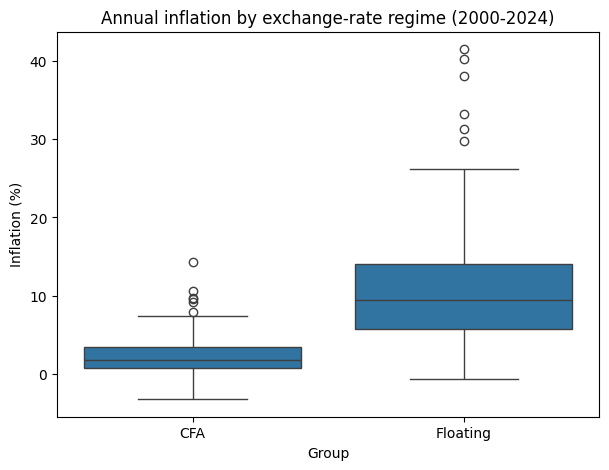

In [4]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="group", y="inflation")
plt.title("Annual inflation by exchange-rate regime (2000-2024)")
plt.xlabel("Group")
plt.ylabel("Inflation (%)")
plt.savefig("../figures/inflation_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation: descriptive statistics

**Level.** The CFA zone's median annual inflation is 1.76%, while the floating-currency group's is 9.44% (means: 2.32% and 11.35%). For CFA countries, the middle 50% of observations fall between 1% and 3.5%, and for floating-currency countries, between 6% and 14%.

**Stability.** The standard deviation is about three times larger in the floating group (8.06 vs 2.74), and its extreme values reach above 40% (maximum 41.51%), against 14.29% in the CFA zone.

**Skewness.** In both groups the mean exceeds the median, which signals right-skewed distributions: a few extreme years pull the mean upward. For this reason, medians are the more reliable measure for comparing the groups, and non-parametric tests may be more appropriate than tests on means.

**Caveats.**
- The stability comparison should be understood carefully because the standard deviation increases mechanically with inflation (a relative metric like the coefficient of variation can complement it).
- A noticeable difference is not yet statistically significant; the following stages test this.
- Even if the difference is substantial, it does not prove that the stable peg is the reason for the lower inflation; other factors could include the size of the nation, exposure to commodities, and political climate.

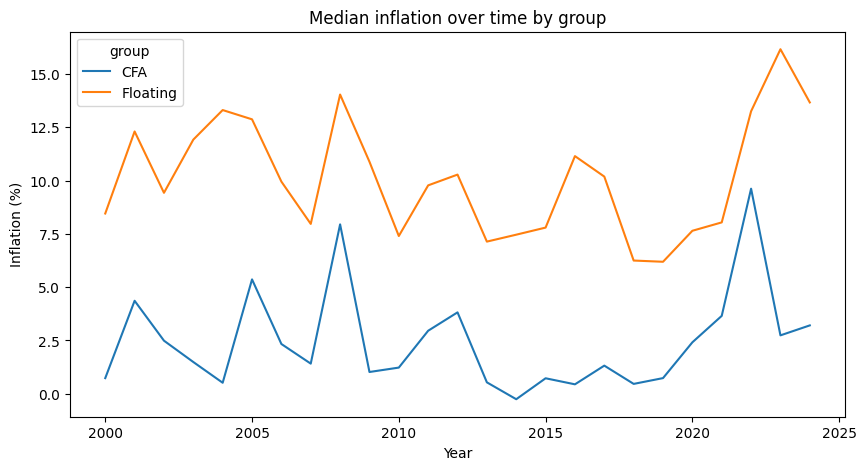

In [5]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x="year", y="inflation", hue="group", estimator="median", errorbar=None)
plt.title("Median inflation over time by group")
plt.xlabel("Year")
plt.ylabel("Inflation (%)")
plt.savefig("../figures/inflation_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation: the evolution of inflation

Both groups' median inflation rises and declines together, peaking in 2008 and 2022–2023. This implies that the CFA peg does not shield member nations from imported inflation and that both groups are vulnerable to common global shocks (food and energy prices).

Nonetheless, the disparity between the groups continues to exist in practically every year. While median inflation in the floating group stays high in 2023–2024, it rapidly declines in the CFA zone following the 2022 peak.

Note: Since just four or five countries are used to calculate each annual median, changes from year to year are sensitive to specific nations and should not be overly construed.